In [32]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [33]:
datas = pd.read_csv('data/penguins.csv',sep=',')
df = datas.dropna()
df = df.loc[(df['flipper_length_mm']<4000) & (df['flipper_length_mm']>0)]
df = pd.get_dummies(df)
df = df.drop('sex_.', axis=1)
scaler = StandardScaler()
df_scaler = scaler.fit_transform(df)
df_scaler = pd.DataFrame(df_scaler, columns = df.columns)
kmeans4 = KMeans(n_clusters=4,random_state=151).fit(df_scaler)
cluster_centers = kmeans4.cluster_centers_

d:\Anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


In [34]:
features = ['喙长','喙深','鳍肢长','重量','雌性','雄性']
angles = np.linspace(0,2*np.pi,len(features),endpoint=False)
angles = np.concatenate((angles,[angles[0]]))
features = np.concatenate((features,[features[0]]))

In [35]:
plt.rcParams['font.family'] = 'Microsoft YaHei'
plt.rcParams['axes.unicode_minus'] = False

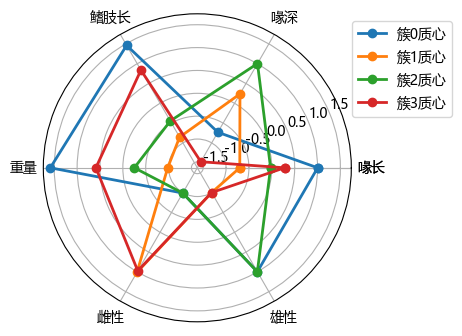

In [36]:
plt.figure(figsize=(8,4))
ax1 = plt.subplot(111,polar=True)

i = 0
for values in cluster_centers:
    values = np.concatenate((values,[values[0]]))
    ax1.plot(angles,values,'o-',linewidth=2,label='簇'+str(i)+'质心')
    i += 1

ax1.set_thetagrids(angles*180/np.pi,features)
plt.legend(bbox_to_anchor=(1.35,1))
plt.show()